The initial goal of this notebook is to query catalogues for the reference clusters. Still TBD on choice, but recommended is Praesepe or Hyades.

In [19]:
from astroquery.vizier import Vizier
Vizier.VIZIER_SERVER = 'vizier.cfa.harvard.edu'

catalog_list = Vizier.find_catalogs('Praesepe')
for k, v in catalog_list.items():
    print(k, ":", v.description)

print(catalog_list['J/ApJ/879/100'])

I/257B : Proper Motions in Praesepe (Wang+, 1995)
J/ApJ/521/682 : Binaries in the Praesepe and Coma clusters (Abt+, 1999)
J/ApJ/697/1578 : A debris disk study of Praesepe (Gaspar+, 2009)
J/ApJ/756/L33 : Radial velocities of 2 hot Jupiters in Praesepe (Quinn+, 2012)
J/ApJ/784/57 : Photometry and proper motions in Praesepe (Wang+, 2014)
J/ApJ/795/161 : Activity and rotation in Praesepe and the Hyades (Douglas+, 2014)
J/ApJ/839/92 : Praesepe members with K2 light curve data (Rebull+, 2017)
J/ApJ/842/83 : Praesepe members rotational periods from K2 LCs (Douglas+, 2017)
J/ApJ/845/72 : The factory & the beehive. III. PTFEB132.707+19.810 (Kraus+, 2017)
J/ApJ/879/100 : K2 rotation periods for Hyades & Praesepe members (Douglas+, 2019)
J/ApJ/904/140 : Ruprecht 147 members & rot. data for 5 other cl. (Curtis+, 2020)
J/ApJ/919/100 : Abundances of 6 stars in Praesepe cluster (Vejar+, 2021)
J/ApJ/921/167 : Rotators in Praesepe with K2 LCs and Gaia EDR3 (Rampalli+, 2021)
J/ApJ/923/23 : Stellar spins

In [20]:
Vizier.ROW_LIMIT = -1
praesepe_lcs = Vizier.get_catalogs("J/MNRAS/442/2081")
praesepe_lcs[0]

HATNet,Type,2MASS,LC,nu,n_nu,1/T,Bmag,Vmag,rmag,Kmag,J-H,J-K,Amp,SNR,Simbad,_RA,_DE
,,,,1 / d,,1 / d,mag,mag,mag,mag,mag,mag,mag,,,deg,deg
str11,str1,str15,str2,float64,str2,float32,float32,float32,float32,float32,float32,float32,float32,float32,str6,float64,float64
269-0000500,b,08401762+194715,LC,0.149427,,0.0011,10.551,9.941,9.837,8.583,0.267,0.303,0.0044,10.5,Simbad,130.07342,19.78750
269-0000588,b,08402231+200624,LC,0.386161,,0.0011,10.554,10.071,10.036,8.852,0.213,0.285,0.0036,7.6,Simbad,130.09296,20.10667
269-0000592,b,08411002+193032,LC,0.345078,,0.0011,10.613,10.080,9.999,8.908,0.243,0.269,0.0045,9.4,Simbad,130.29175,19.50889
269-0000667,b,08395234+191845,LC,0.309961,,0.0011,10.742,10.217,10.119,9.008,0.192,0.275,0.0042,8.3,Simbad,129.96808,19.31250
269-0000673,b,08400062+194823,LC,0.333975,,0.0011,10.824,10.271,10.161,9.079,0.184,0.251,0.0072,6.5,Simbad,130.00258,19.80639
269-0000610,d,08393042+200408,LC,0.140742,,0.0011,10.892,10.260,10.155,8.807,0.301,0.333,0.0054,5.9,Simbad,129.87675,20.06889
269-0000701,d,08405252+192859,LC,0.248768,,0.0011,10.839,10.267,10.173,9.049,0.183,0.288,0.0047,5.7,Simbad,130.21883,19.48306
317-0000737,b,08413154+183002,LC,0.240999,,0.0011,10.886,10.384,10.246,9.105,0.221,0.259,0.0075,12.8,Simbad,130.38142,18.50056


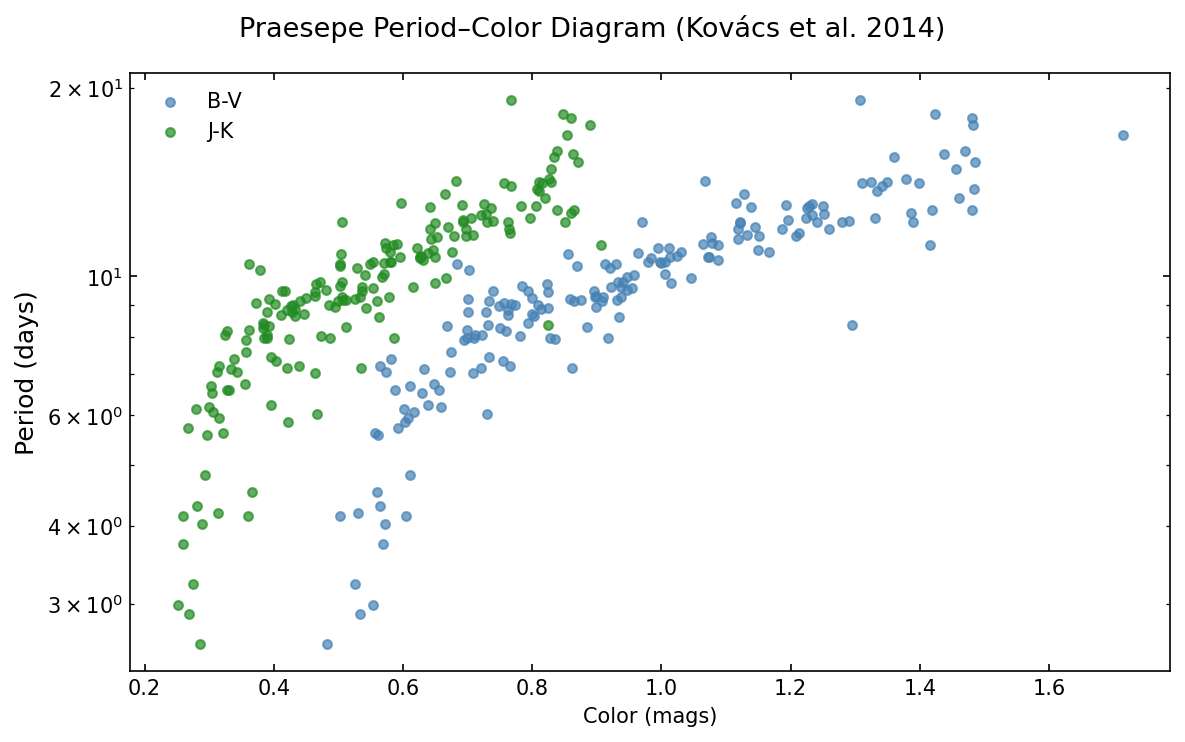

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from astroquery.vizier import Vizier

# 1. Fetch the full catalog directly (or replace with pd.read_csv/astropy.table.Table.read for your local file)
v = Vizier(columns=['*'], row_limit=-1)
cat = Vizier.get_catalogs("J/MNRAS/442/2081")[0]

# 2. Extract frequency (nu in 1/d) and magnitudes
nu = np.array(cat['nu'], dtype=float)
b_mag = np.array(cat['Bmag'], dtype=float)
v_mag = np.array(cat['Vmag'], dtype=float)
j_k = np.array(cat['J-K'], dtype=float) 
period = 1.0 / nu  
bv_color = b_mag - v_mag

# 3. Highlight your specific target (HAT-269-0000500)
target_mask = np.array(cat['HATNet']) == '269-0000500'

# 4. Plot Period vs. Color
fig, (ax1) = plt.subplots(figsize=(8, 5), dpi=150)

ax1.scatter(bv_color, period, s=18, alpha=0.7, color='steelblue', label='B-V')
ax1.set_yscale('log')
ax1.set_xlabel('Color (mags)')
ax1.set_ylabel('Period (days)', fontsize=12)
ax1.tick_params(axis='both', which='both', direction='in', top=True, right=True)
ax1.scatter(j_k, period, s=18, alpha=0.7, color='forestgreen', label='J-K')
ax1.legend(frameon=False)
fig.suptitle('Praesepe Period–Color Diagram (Kovács et al. 2014)', fontsize=13)
plt.tight_layout()


## Plotting period vs bp-rp for a few reference clusters

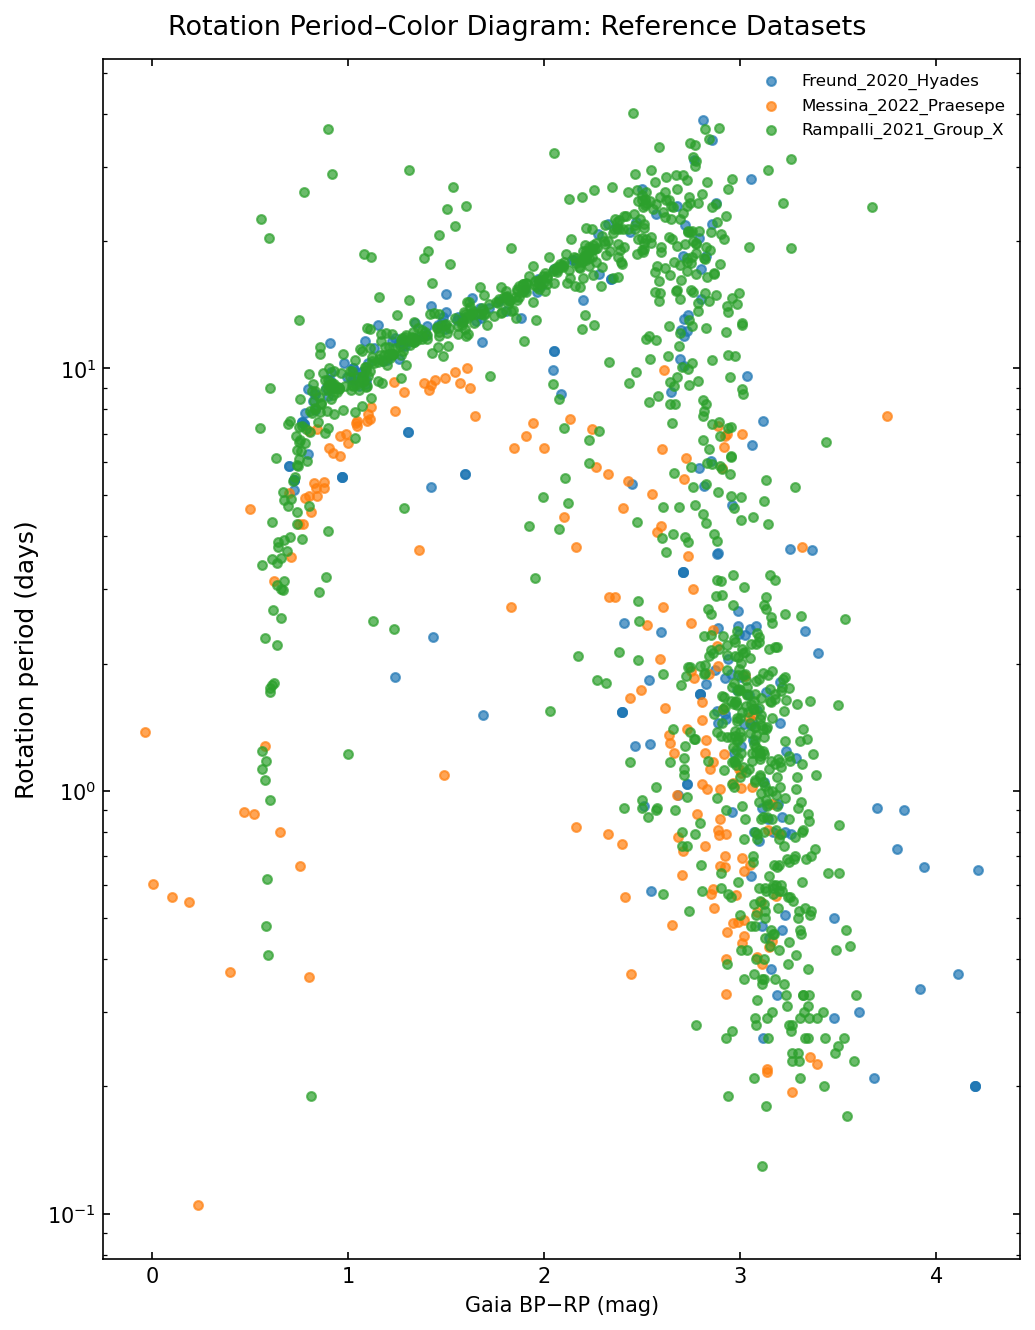

In [ ]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path(
    "/Users/nwansbacher/Desktop/UNC YEAR 3/ASTR 519/FINAL PROJECT/reference_datasets"
)
files = sorted(data_dir.glob("*.csv"))

if not files:
    raise FileNotFoundError(f"No CSV files found in {data_dir}")

fig, ax = plt.subplots(figsize=(7, 9), dpi=150)
plotted = 0

for file in files:
    cat = pd.read_csv(file, sep=None, engine="python")
    cols = {
        re.sub(r"[^a-z0-9]", "", str(c).lower()): c
        for c in cat.columns
    }

    period_col = cols.get("prot") or cols.get("per")
    if period_col is None:
        print(f"Skipping {file.name}: no Prot or Per column")
        continue

    color_col = cols.get("bprp")
    if color_col:
        color = pd.to_numeric(cat[color_col], errors="coerce")
    else:
        bp_col = cols.get("bpmag") or cols.get("photbpmeanmag") or cols.get("bp")
        rp_col = cols.get("rpmag") or cols.get("photrpmeanmag") or cols.get("rp")
        if bp_col is None or rp_col is None:
            print(f"Skipping {file.name}: no BP-RP or BP/RP columns")
            continue
        color = (
            pd.to_numeric(cat[bp_col], errors="coerce")
            - pd.to_numeric(cat[rp_col], errors="coerce")
        )

    period = pd.to_numeric(cat[period_col], errors="coerce")
    valid = np.isfinite(color) & np.isfinite(period) & (period > 0)

    if not valid.any():
        print(f"Skipping {file.name}: no valid color-period rows")
        continue

    ax.scatter(color[valid], period[valid], s=18, alpha=0.7, label=file.stem)
    plotted += 1
if not plotted:
    raise ValueError("No files with valid BP-RP and Prot data were plotted.")

ax.set_yscale("log")
ax.set_xlabel("Gaia BP−RP (mag)")
ax.set_ylabel("Rotation period (days)", fontsize=12)
ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)
ax.legend(frameon=False, fontsize=8)
fig.suptitle("Rotation Period–Color Diagram: Reference Datasets", fontsize=13)
fig.tight_layout()

ax.scatter(
    plot_data["bp_rp"],
    plot_data["best_period_days"],
    marker="s",
    color="black",
    s=36,
    alpha=0.9,
    label="Oceanus Lomb–Scargle",
    zorder=10,
)

plt.show()

### Attempting to load the csv files from Atchuthan for our candidates

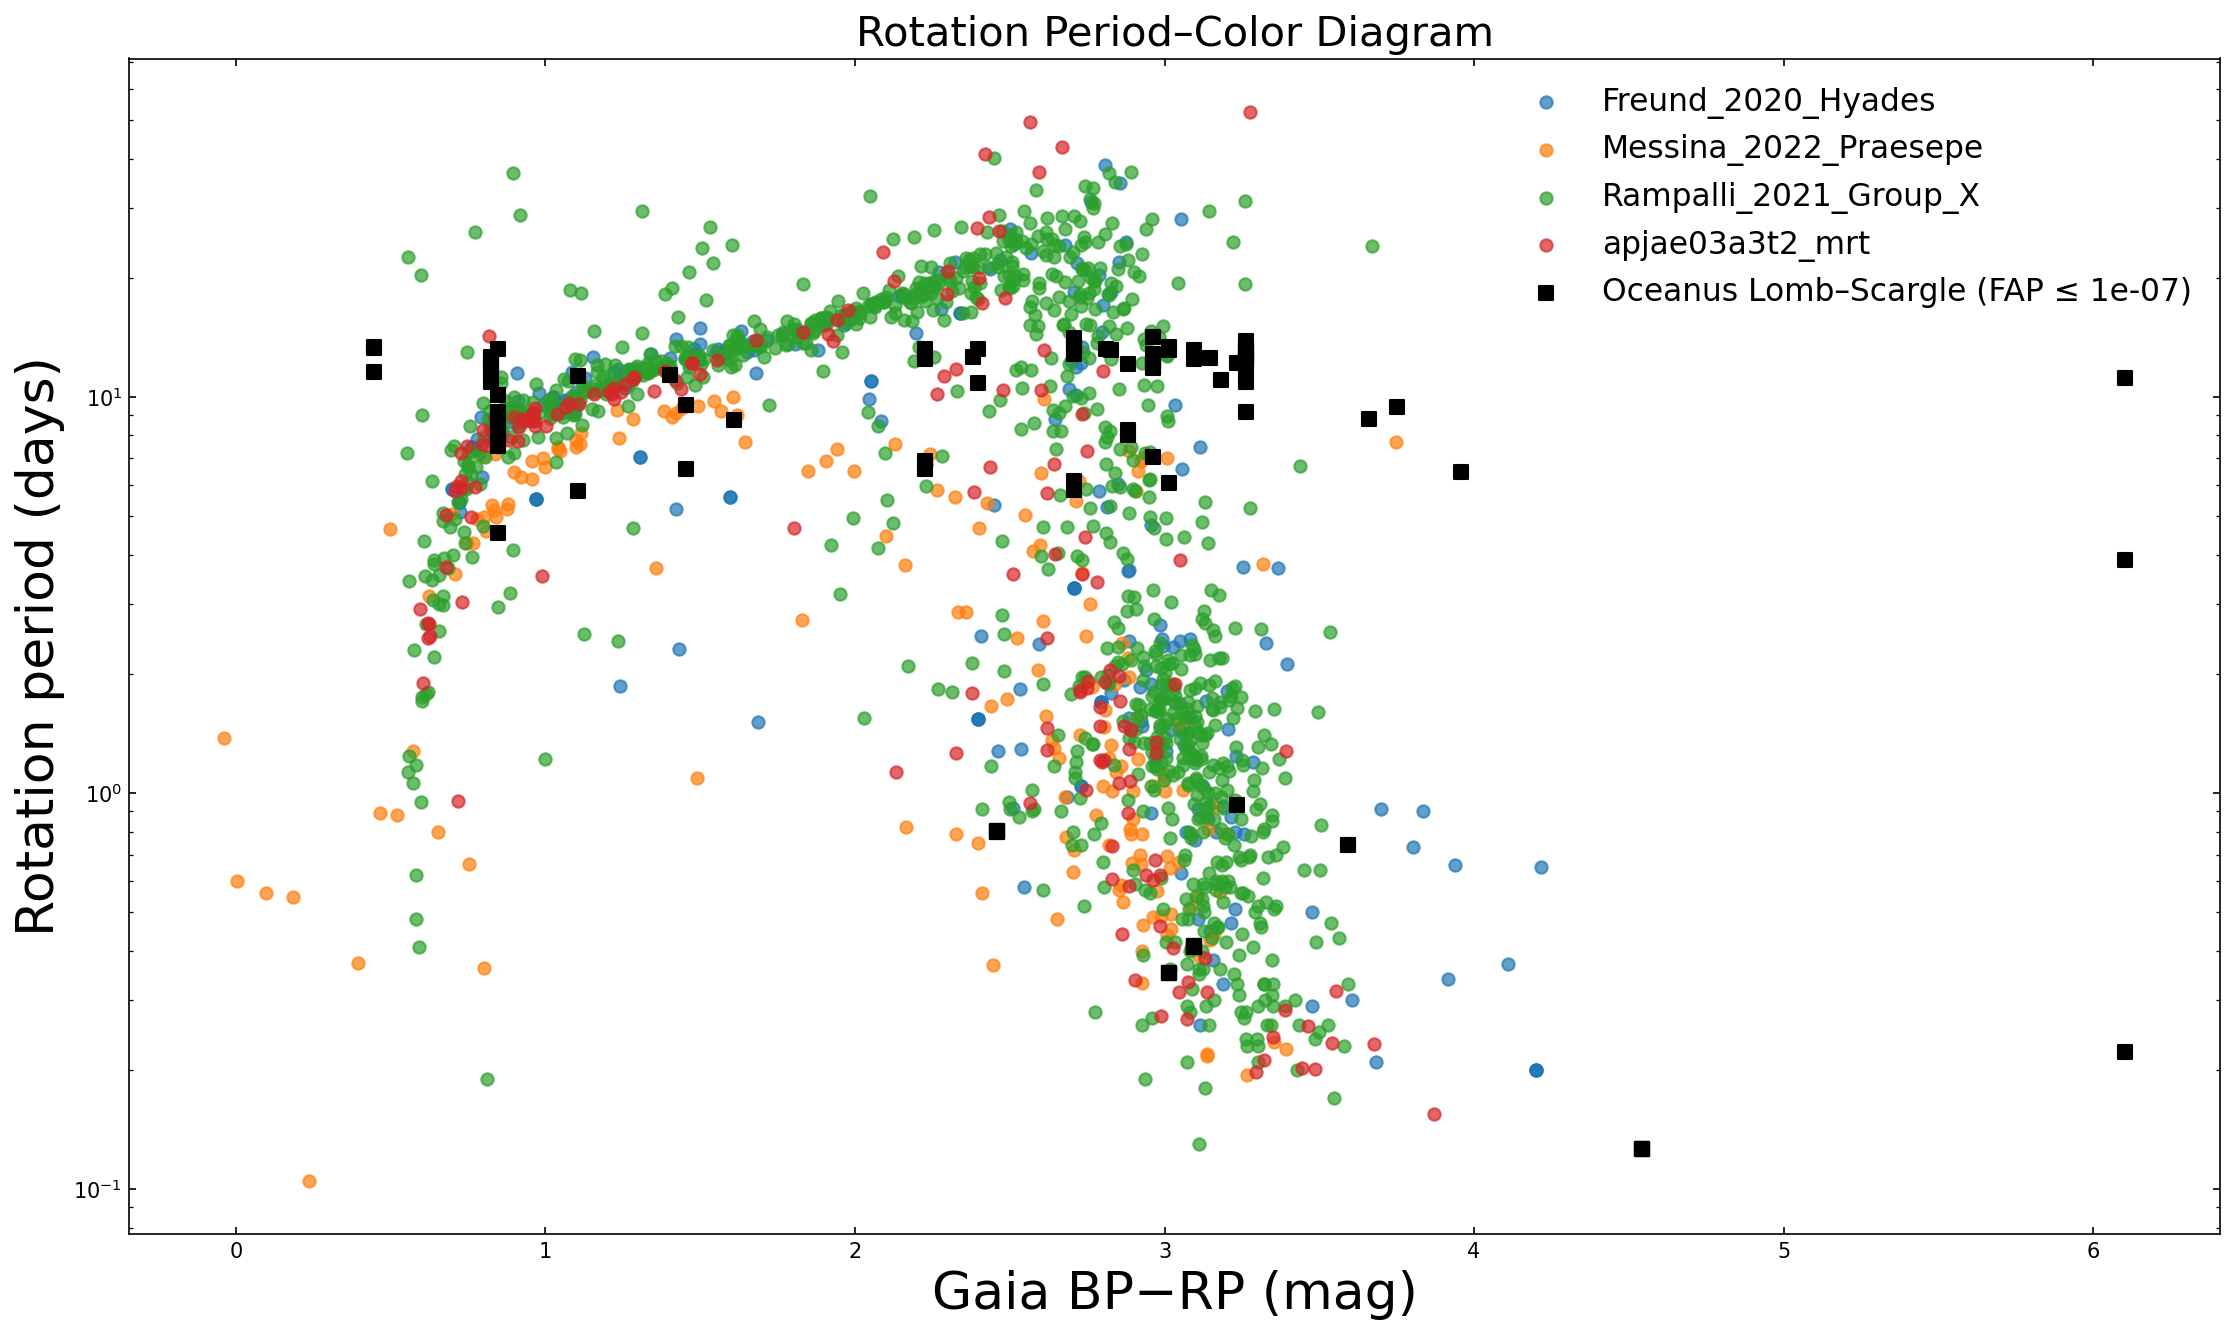

Oceanus period points plotted: 110


In [53]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path(
    "/Users/nwansbacher/Desktop/UNC YEAR 3/ASTR 519/FINAL PROJECT"
)
reference_dir = project_dir / "reference_datasets"
members_path = project_dir / "oceanus_members_gaia_dr3.csv"
periods_path = (
    project_dir
    / "Oceanus_cubes_and_extraction_tutorial"
    / "targets_periods_output.csv"
)

# Read the CDS fixed-width table; read other datasets as delimited text.
def read_reference(file):
    if file.name == "apjae03a3t2_mrt.txt":
        data = pd.read_fwf(
            file,
            skiprows=66,
            header=None,
            colspecs=[(177, 183), (206, 212)],
            names=["bp_rp", "Prot"],
        )
    else:
        data = pd.read_csv(file, sep=None, engine="python")

    # Normalize headers so BP-RP, bp_rp, and similar names match.
    columns = {
        re.sub(r"[^a-z0-9]", "", str(name).lower()): name
        for name in data.columns
    }

    period_col = columns.get("prot") or columns.get("per")
    if period_col is None:
        print(f"Skipping {file.name}: no Prot or Per column")
        return None, None

    # Use an existing color when available; otherwise calculate BP - RP.
    color = pd.Series(np.nan, index=data.index, dtype=float)
    color_col = columns.get("bprp")
    if color_col is not None:
        color = pd.to_numeric(data[color_col], errors="coerce")

    bp_col = columns.get("bpmag") or columns.get("photbpmeanmag") or columns.get("bp")
    rp_col = columns.get("rpmag") or columns.get("photrpmeanmag") or columns.get("rp")
    if bp_col is not None and rp_col is not None:
        bp = pd.to_numeric(data[bp_col], errors="coerce")
        rp = pd.to_numeric(data[rp_col], errors="coerce")
        color = color.fillna(bp - rp)

    if color.isna().all():
        print(f"Skipping {file.name}: no BP-RP or BP/RP columns")
        return None, None

    return color, pd.to_numeric(data[period_col], errors="coerce")


fig, ax = plt.subplots(figsize=(15, 9), dpi=150)

# Plot each reference dataset.
files = sorted(
    file for file in reference_dir.iterdir()
    if file.suffix.lower() in {".csv", ".txt"}
)
if not files:
    raise FileNotFoundError(f"No CSV or TXT files found in {reference_dir}")

for file in files:
    color, period = read_reference(file)
    if color is None:
        continue

    valid = np.isfinite(color) & np.isfinite(period) & (period > 0)
    if valid.any():
        ax.scatter(
            color[valid],
            period[valid],
            s=35,
            alpha=0.7,
            label=file.stem,
        )
    else:
        print(f"Skipping {file.name}: no valid color-period rows")

# Keep only significant Lomb-Scargle results before matching Gaia colors.
FAP_MAX = 1e-7
members = pd.read_csv(members_path)
periods = pd.read_csv(periods_path)

periods["false_alarm_probability"] = pd.to_numeric(
    periods["false_alarm_probability"], errors="coerce"
)
periods["best_period_days"] = pd.to_numeric(
    periods["best_period_days"], errors="coerce"
)
periods = periods.loc[
    periods["period_status"].eq("period_found")
    & periods["false_alarm_probability"].le(FAP_MAX)
    & periods["best_period_days"].gt(0)
].copy()

# Use either Gaia BP-RP column and match targets by trimmed name.
members["bp_rp"] = pd.to_numeric(
    members["bp_rp_x"], errors="coerce"
).combine_first(
    pd.to_numeric(members["bp_rp_y"], errors="coerce")
)
members["match_name"] = members["Name"].astype("string").str.strip()
periods["match_name"] = periods["name"].astype("string").str.strip()

plot_data = periods.merge(
    members[["match_name", "bp_rp"]],
    on="match_name",
    how="left",
    validate="many_to_one",
)
plot_data = plot_data.loc[
    np.isfinite(plot_data["bp_rp"])
    & np.isfinite(plot_data["best_period_days"])
]

# Overlay significant Oceanus periods as black squares.
if not plot_data.empty:
    ax.scatter(
        plot_data["bp_rp"],
        plot_data["best_period_days"],
        marker="s",
        color="black",
        s=40,
        label=f"Oceanus Lomb–Scargle (FAP ≤ {FAP_MAX:g})",
        zorder=10,
    )

ax.set_yscale("log")
ax.set_xlabel("Gaia BP−RP (mag)",fontsize=25)
ax.set_ylabel("Rotation period (days)",fontsize=25)
ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)
ax.legend(frameon=False, fontsize=15)
ax.set_title("Rotation Period–Color Diagram",fontsize=20)
fig.tight_layout()
plt.show()

print(f"Oceanus period points plotted: {len(plot_data)}")